# 03 - Anomaly detection

Models trained on normal traffic only, so they never see an attack before test time.
Same splits, same threshold rule (1% FPR on validation) and same `results.json` as `02_supervised`, so the numbers are directly comparable.

## Setup

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.metrics import roc_auc_score
from sklearn.pipeline import make_pipeline

from netad.data import load_unsw_frame, overlap_with_train, train_val_split, CATEGORICAL, FEATURES
from netad.preprocessing import build_preprocessor
from netad.evaluation import (
    FIGURES_DIR, RESULTS_PATH, evaluate_binary, choose_threshold, evaluate_test, save_result, results_table,
)

In [3]:
train_df = load_unsw_frame("train")
test_df = load_unsw_frame("test")

X_test = test_df[FEATURES]
y_test = test_df["label"]
y_test_multi = test_df["attack_cat"]
unseen = ~overlap_with_train(train_df, test_df)

X_tr, X_val, y_tr, y_val = train_val_split(train_df, "label")
val_categories = train_df.loc[X_val.index, "attack_cat"]
X_normal = X_tr[y_tr == 0]

MAX_FPR = 0.01

len(X_normal), len(X_tr), len(X_val), len(X_test)

(41367, 80752, 20189, 82332)

Training uses only the normal rows of the training part. The preprocessor is fitted on them too, so protocols and services that only attacks use end up in the "infrequent" one-hot column.

Validation keeps both classes. With an FPR budget the threshold is set by how normal validation flows score (about their 99th percentile), attack labels don't move it.

## Isolation Forest

Random trees that split on random features at random values. A flow that gets isolated after few splits is unusual. Anomaly score: `-score_samples` (higher = more anomalous). `contamination` is not used, the threshold comes from validation like for the other models.

A few settings are compared on validation partial ROC-AUC (FPR <= 1%): how many normal flows each tree is built on (`max_samples`, 1.0 = all of them) and whether the one-hot columns are used, since random splits on 0/1 columns isolate little. This uses the attack labels of validation, so the choice is not completely label free; the grid is kept small for that reason.

In [4]:
def anomaly_scores(model, X):
    return -model.score_samples(X)


columns = {"all": None, "numeric only": CATEGORICAL}

iforest = {}
for max_samples in [256, 1024, 4096, 16384, 1.0]:
    for cols, exclude in columns.items():
        model = make_pipeline(
            build_preprocessor(exclude=exclude),
            IsolationForest(n_estimators=300, max_samples=max_samples, random_state=42, n_jobs=-1),
        ).fit(X_normal)
        s_val = anomaly_scores(model, X_val)
        iforest[(len(X_normal) if max_samples == 1.0 else max_samples, cols)] = {
            "model": model,
            "params": {"n_estimators": 300, "max_samples": max_samples, "excluded": exclude or []},
            "val_pauc": roc_auc_score(y_val, s_val, max_fpr=MAX_FPR),
            "val_roc_auc": roc_auc_score(y_val, s_val),
        }

pd.DataFrame(
    {k: {"val pAUC": v["val_pauc"], "val ROC-AUC": v["val_roc_auc"]} for k, v in iforest.items()}
).T.rename_axis(["max_samples", "columns"]).round(4)

val pAUC  val ROC-AUC
max_samples columns                            
256         all             0.4987       0.7665
            numeric only    0.4984       0.8311
1024        all             0.5090       0.7747
            numeric only    0.5026       0.8128
4096        all             0.5187       0.7810
            numeric only    0.5130       0.8068
16384       all             0.5371       0.7926
            numeric only    0.5265       0.8088
41367       all             0.5459       0.7950
            numeric only    0.5352       0.8067

In [5]:
best = max(iforest.values(), key=lambda v: v["val_pauc"])
model = best["model"]
best["params"]

{'n_estimators': 300, 'max_samples': 1.0, 'excluded': []}

In [6]:
s_val = anomaly_scores(model, X_val)
s_test = anomaly_scores(model, X_test)
threshold = choose_threshold(y_val, s_val, "fpr", max_fpr=MAX_FPR)

metrics = {
    "val": evaluate_binary(y_val, s_val, threshold, categories=val_categories),
    **evaluate_test(evaluate_binary, y_test, s_test, unseen, categories=y_test_multi, threshold=threshold),
}
save_result("IsolationForest", "binary", metrics, {"threshold_mode": "fpr", "max_fpr": MAX_FPR, **best["params"]})

pd.DataFrame({k: {m: v[m] for m in ["recall", "fpr", "precision", "f1", "roc_auc", "pr_auc"]} for k, v in metrics.items()}).T.round(4)

,recall,fpr,precision,f1,roc_auc,pr_auc
val,0.1688,0.0100,0.9416,0.2863,0.7950,0.7993
test,0.6119,0.0264,0.9660,0.7492,0.8811,0.9121
test_unseen,0.5751,0.0254,0.9606,0.7195,0.8708,0.8957


Recall on validation and on test are far apart. Per category, with the share of each category among the attacks:

In [7]:
def per_category(m):
    cats = {c: v for c, v in m["by_category"].items() if c != "Normal"}
    total = sum(v["n"] for v in cats.values())
    return pd.DataFrame({c: {"share of attacks": v["n"] / total, "flagged": v["flagged"]} for c, v in cats.items()}).T


pd.concat({"val": per_category(metrics["val"]), "test": per_category(metrics["test"])}, axis=1).round(3)

val                     test        
               share of attacks flagged share of attacks flagged
Analysis                  0.011   0.241            0.015   0.885
Backdoor                  0.010   0.456            0.013   0.909
DoS                       0.061   0.285            0.090   0.699
Exploits                  0.380   0.157            0.246   0.358
Fuzzers                   0.303   0.033            0.134   0.225
Generic                   0.080   0.864            0.416   0.957
Reconnaissance            0.130   0.040            0.077   0.096
Shellcode                 0.022   0.000            0.008   0.000
Worms                     0.002   0.167            0.001   0.159

Scores of normal flows, validation vs test, against the threshold (same check as for the random forest in `02_supervised`):

In [8]:
normal_val = s_val[(y_val == 0).to_numpy()]
normal_test = s_test[(y_test == 0).to_numpy()]

pd.DataFrame({
    "validation": pd.Series(normal_val).quantile([0.5, 0.9, 0.95, 0.99]),
    "test": pd.Series(normal_test).quantile([0.5, 0.9, 0.95, 0.99]),
}).rename_axis("quantile").round(4).assign(threshold=round(threshold, 4))

,validation,test,threshold
quantile,,,
0.50,0.3822,0.3974,0.5574
0.90,0.4493,0.4757,0.5574
0.95,0.4764,0.5079,0.5574
0.99,0.5573,0.6004,0.5574


## Comparison with the supervised models

All binary models in `results.json`, threshold at 1% FPR on validation for each.

In [9]:
cols = ["recall", "fpr", "precision", "roc_auc", "pr_auc"]
pd.concat({subset: results_table("binary", subset, cols) for subset in ["test", "test_unseen"]}, axis=1).round(4)

test                                   test_unseen  \
                       recall     fpr precision roc_auc  pr_auc      recall   
Dummy (prior)          0.0000  0.0000    0.0000  0.5000  0.5506      0.0000   
LogisticRegression     0.8042  0.0252    0.9751  0.9676  0.9738      0.7719   
RandomForest           0.8905  0.0397    0.9649  0.9816  0.9861      0.8710   
HistGradientBoosting   0.9195  0.0481    0.9591  0.9849  0.9888      0.9063   
RandomForest (no TTL)  0.8856  0.0425    0.9623  0.9801  0.9849      0.8651   
IsolationForest        0.6119  0.0264    0.9660  0.8811  0.9121      0.5751   

                                                         
                          fpr precision roc_auc  pr_auc  
Dummy (prior)          0.0000    0.0000  0.5000  0.5185  
LogisticRegression     0.0234    0.9727  0.9632  0.9666  
RandomForest           0.0374    0.9616  0.9791  0.9821  
HistGradientBoosting   0.0474    0.9537  0.9828  0.9856  
RandomForest (no TTL)  0.0400    0.9589  0.9774  0.9806  
IsolationForest        0.0254    0.9606  0.8708  0.8957

### Repeated flows in test

Validation has one row per feature vector, test is used as published and repeats some flows many times. Both models on the distinct rows of test (each feature vector + category counted once). The random forest is refit with the hyperparameters and threshold saved by `02_supervised`.

In [10]:
entry = next(r for r in json.loads(RESULTS_PATH.read_text(encoding="utf-8"))
             if (r["model"], r["task"]) == ("RandomForest", "binary"))
rf_params = {k: v for k, v in entry["params"].items() if k in RandomForestClassifier().get_params()}
rf = make_pipeline(build_preprocessor(), RandomForestClassifier(random_state=42, n_jobs=-1, **rf_params)).fit(X_tr, y_tr)

test_scores = {
    "RandomForest": (rf.predict_proba(X_test)[:, 1], entry["test"]["threshold"]),
    "IsolationForest": (s_test, threshold),
}
distinct = ~test_df.duplicated(FEATURES + ["attack_cat"]).to_numpy()

repeated = {}
for name, (scores, t) in test_scores.items():
    for rows, mask in [("all rows", np.ones(len(X_test), dtype=bool)), ("distinct rows", distinct)]:
        repeated[(name, rows)] = evaluate_binary(y_test[mask], scores[mask], t, categories=y_test_multi[mask])

pd.DataFrame({k: {m: v[m] for m in ["n", "recall", "fpr", "precision"]} for k, v in repeated.items()}).T.round(4)

n  recall     fpr  precision
RandomForest    all rows       82332.0  0.8905  0.0397     0.9649
                distinct rows  55945.0  0.7984  0.0395     0.9278
IsolationForest all rows       82332.0  0.6119  0.0264     0.9660
                distinct rows  55945.0  0.2948  0.0180     0.9122

In [11]:
pd.DataFrame({
    k: {c: v["flagged"] for c, v in m["by_category"].items()} for k, m in repeated.items()
}).round(3)

RandomForest               IsolationForest              
                   all rows distinct rows        all rows distinct rows
Analysis              0.914         0.870           0.885         0.825
Backdoor              0.988         0.980           0.909         0.847
DoS                   0.957         0.919           0.699         0.391
Exploits              0.942         0.928           0.358         0.174
Fuzzers               0.382         0.303           0.225         0.115
Generic               0.992         0.976           0.957         0.800
Normal                0.040         0.039           0.026         0.018
Reconnaissance        0.962         0.954           0.096         0.096
Shellcode             0.870         0.870           0.000         0.000
Worms                 0.932         0.932           0.159         0.159

Detection rate per attack category on test, Isolation Forest vs the best supervised model (random forest):

In [12]:
saved = {
    name: results_table("binary", "test", ["by_category"]).loc[name, "by_category"]
    for name in ["RandomForest", "IsolationForest"]
}
by_category = pd.DataFrame({name: {c: v["flagged"] for c, v in cats.items()} for name, cats in saved.items()})
by_category["n"] = pd.Series({c: v["n"] for c, v in saved["IsolationForest"].items()})
by_category.round(3)

,RandomForest,IsolationForest,n
Analysis,0.914,0.885,677
Backdoor,0.988,0.909,583
DoS,0.957,0.699,4089
Exploits,0.942,0.358,11132
Fuzzers,0.382,0.225,6062
Generic,0.992,0.957,18871
Normal,0.040,0.026,37000
Reconnaissance,0.962,0.096,3496
Shellcode,0.870,0.000,378
Worms,0.932,0.159,44


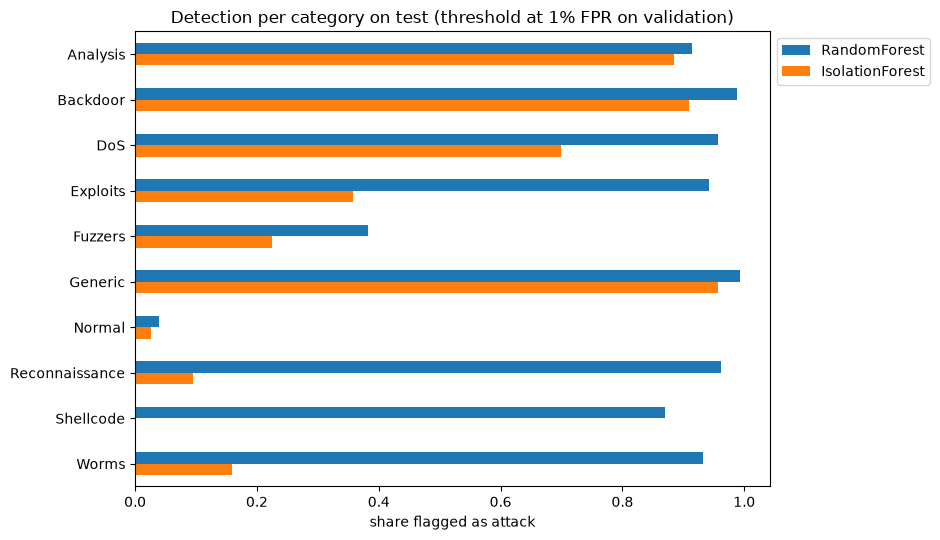

In [13]:
ax = by_category[["RandomForest", "IsolationForest"]].plot.barh(figsize=(9.5, 5.5))
ax.invert_yaxis()
ax.set_xlabel("share flagged as attack")
ax.set_title("Detection per category on test (threshold at 1% FPR on validation)")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
ax.figure.tight_layout()
ax.figure.savefig(FIGURES_DIR / "anomaly_detection_by_category.png", dpi=120)
plt.show()

## Conclusions

1. **Isolation Forest is far behind the supervised models.** With the same rule (threshold at 1% FPR on validation) it flags 61% of test attacks at 2.6% FPR, the random forest 89% at 4.0%. ROC-AUC is 0.88 vs 0.98. Expected: the random forest was shown what attacks look like, Isolation Forest only knows normal traffic.
2. **Most of that 61% comes from repeated flows.** Counting each distinct test flow once, recall drops to 29% (random forest: 89% -> 80%). The attacks test repeats most (Generic, DoS, Exploits) are among the easiest to isolate. The 17% on validation, where every flow appears once, was closer to the truth; the rest of the gap is the attack mix (Generic is 8% of validation attacks and 42% of test attacks) and normal flows scoring higher on test.
3. **It catches attacks that look unusual, not the ones that blend in.** On distinct test rows: Backdoor 85%, Analysis 83%, Generic 80%, DoS 39%, Exploits 17%, Fuzzers 12%, Reconnaissance 10%, Shellcode 0%. The random forest stays above 87% on all of them except Fuzzers (30%).
4. **The FPR shifts on test here too, less than for the random forest.** 1% on validation becomes 2.6% on test (1.8% on distinct normal flows), against 4.0% for the random forest. 99th percentile of the normal scores: 0.557 on validation, 0.600 on test.
5. **Settings.** More normal flows per tree helps steadily (validation pAUC 0.499 with 256, 0.546 with all 41,367). Dropping the one-hot columns raises the full ROC-AUC on validation but lowers pAUC, which is the region where the alert threshold sits. Even the best setting stays close to 0.5 pAUC: below 1% FPR it ranks the validation attacks barely better than chance.
6. **Not answered yet:** whether it catches attack types a supervised model has never seen, which is what anomaly detection is for. That is the leave-one-attack-out experiment, run together with the autoencoder.